In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
from gprofiler import GProfiler
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3


from datetime import date
import sys
sys.path.append("/storage/groups/ml01/workspace/jan.domke/Code/")
import scib_excerpts
import plot_ma
import gprofiler_custom_LISA

In [2]:
#Import color palette to get consistent colors across figures
import pickle  
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

In [3]:
new_reds = plot_ma.shiftedColorMap(plot_ma.matplotlib.cm.Reds, midpoint=0.7, name='shifted')

In [4]:
today = date.today()
date = today.strftime("%d_%m_%Y")

In [5]:
# Import datasets with Milos differential abundance values for k = 50
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_scarches_labeled_milo.h5ad")

In [6]:
# Import milo logFC values calculated with k=150
denovo_recalc_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_scarches_labeled_logFC.h5ad")

In [7]:
# Update milo logFC values with new ones calculated with k=150
denovo_recalc.obs.logFC_avg = denovo_recalc_logFC_avg
denovo_ref.obs.logFC_avg = denovo_ref_logFC_avg
scarches_unlabeled.obs.logFC_avg = scarches_unlabeled_logFC_avg
scarches_labeled.obs.logFC_avg = scarches_labeled_logFC_avg

In [8]:
healthy_studies = ["Meyer_2021"]
healthy_datasets = ["Meyer_2021_5prime", "Meyer_2021_3prime"]

In [9]:
# Show how many cells,datasets,studies are included in reference and query
ncells = denovo_recalc.obs.groupby("origin").size()
ndata = denovo_recalc.obs.groupby("origin").dataset.nunique()
nstudy = denovo_recalc.obs.groupby("origin").study.nunique()

names = ["cells", "datasets", "studies"]
counts_healthy = pd.concat([ncells,ndata,nstudy],axis=1)
counts_healthy = counts_healthy.rename({0:"cells"},axis=1)
counts_healthy

,cells,dataset,study
origin,,,
query,128628,2,1
reference,584884,14,11


In [10]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("string")
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("category")

In [11]:
# calculate differential embedding score
scarches_unlabeled.obs["diff_denovo_recalc"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_unlabeled.obs["diff_denovo_ref"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_unlabeled.obs["diff_scArches_labeled"] = abs(scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_recalc"] = abs(scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_ref"] = abs(scarches_labeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_labeled.obs["diff_scArches_unlabeled"] = abs(scarches_labeled.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_ref.obs["diff_denovo_recalc"] = abs(denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
denovo_ref.obs["diff_scArches_labeled"] = abs(denovo_ref.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_ref.obs["diff_scArches_unlabeled"] = abs(denovo_ref.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_unlabeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_labeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_recalc.obs["diff_denovo_ref"] = abs(denovo_recalc.obs.logFC_avg - denovo_ref.obs.logFC_avg)

In [12]:
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']

In [13]:
scarches_unlabeled_plot = sc.pp.subsample(scarches_unlabeled, fraction=1., copy=True)
scarches_labeled_plot = sc.pp.subsample(scarches_labeled, fraction=1., copy=True)
denovo_ref_plot = sc.pp.subsample(denovo_ref, fraction=1., copy=True)
denovo_recalc_plot = sc.pp.subsample(denovo_recalc, fraction=1., copy=True)

# 1. Plots

In [17]:
meyer_healthy = scarches_unlabeled[scarches_unlabeled.obs.study == "Meyer_2021"]

In [21]:
meyer_healthy.obs.groupby("subject_ID").logFC_avg.mean()

subject_ID
386C   -1.296478
411C   -0.203203
428C   -2.011807
453C   -2.384246
464C   -2.609810
466C   -2.028732
490C   -1.149107
Name: logFC_avg, dtype: float64

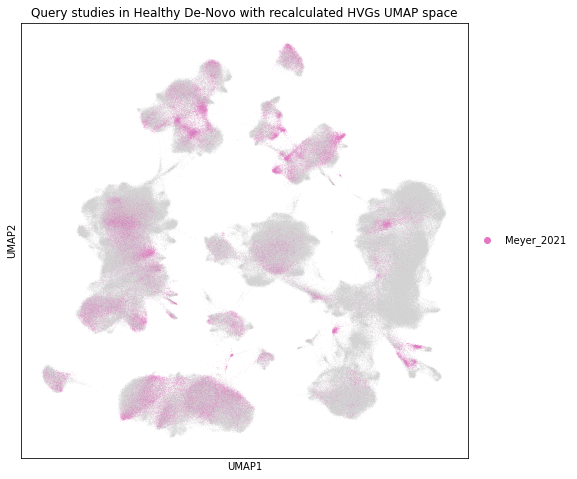

In [13]:
sc.pl.umap(denovo_recalc_plot, color="study",  size = 0.5, sort_order = False, groups = healthy_studies,
          title = "Query studies in Healthy De-Novo with recalculated HVGs UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

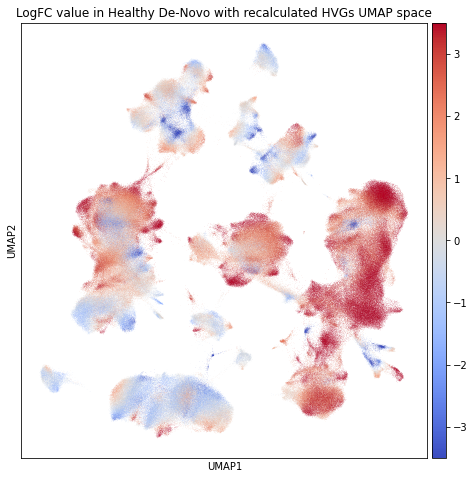

In [16]:
sc.pl.umap(denovo_recalc_plot, color="logFC_avg",color_map="coolwarm",vmin=-3.5,vmax=3.5, size = 0.3, sort_order = False,
          title = "LogFC value in Healthy De-Novo with recalculated HVGs UMAP space"
          #save = f"_healthy_denovo_recalc_logFC_{date}.png"
          )

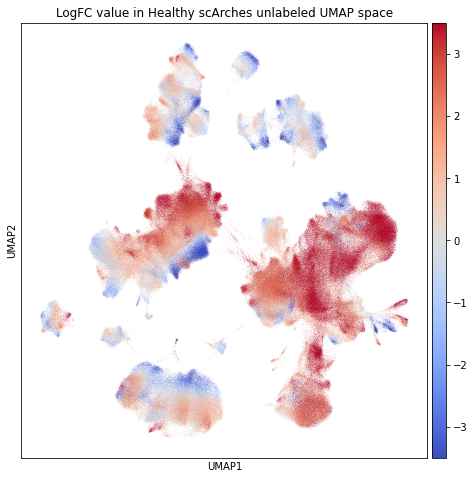

In [18]:
sc.pl.umap(scarches_unlabeled_plot, color="logFC_avg", color_map = "coolwarm", vmin=-3.5,vmax=3.5, size = 0.3, sort_order = False,
          title = "LogFC value in Healthy scArches unlabeled UMAP space",
          save = f"_healthy_scarches_unlabeled_logFC_{date}.png")

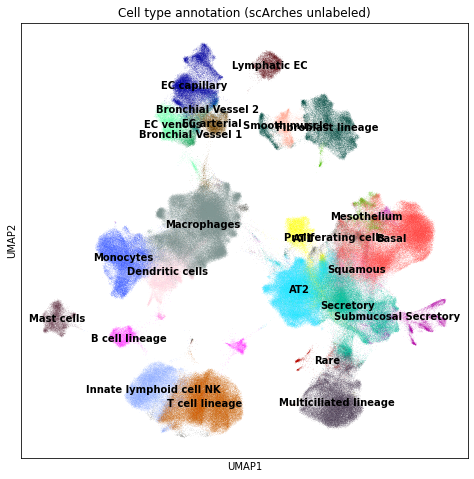

In [19]:
sc.pl.umap(scarches_unlabeled_plot, color = "C_scArches", palette = colordict, legend_loc = "on data", size = 0.3, sort_order = False,
          title = "Cell type annotation (scArches unlabeled)",
          save = f"_healthy_scarches_unlabeled_annotation_{date}.png")

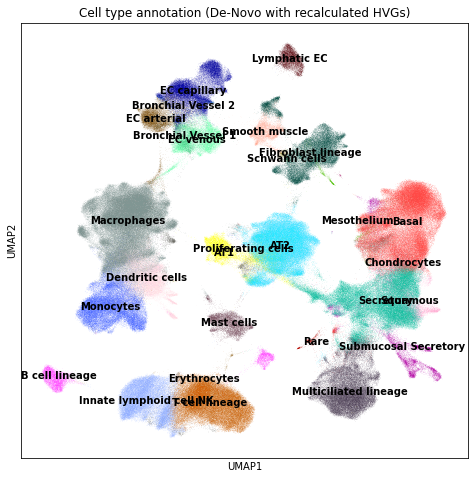

In [20]:
sc.pl.umap(denovo_recalc_plot, color = "C_scANVI", palette = colordict, legend_loc = "on data", size = 0.3, sort_order = False,
          title = "Cell type annotation (De-Novo with recalculated HVGs)",
          save = f"_healthy_denovo_recalc_annotation_{date}.png")

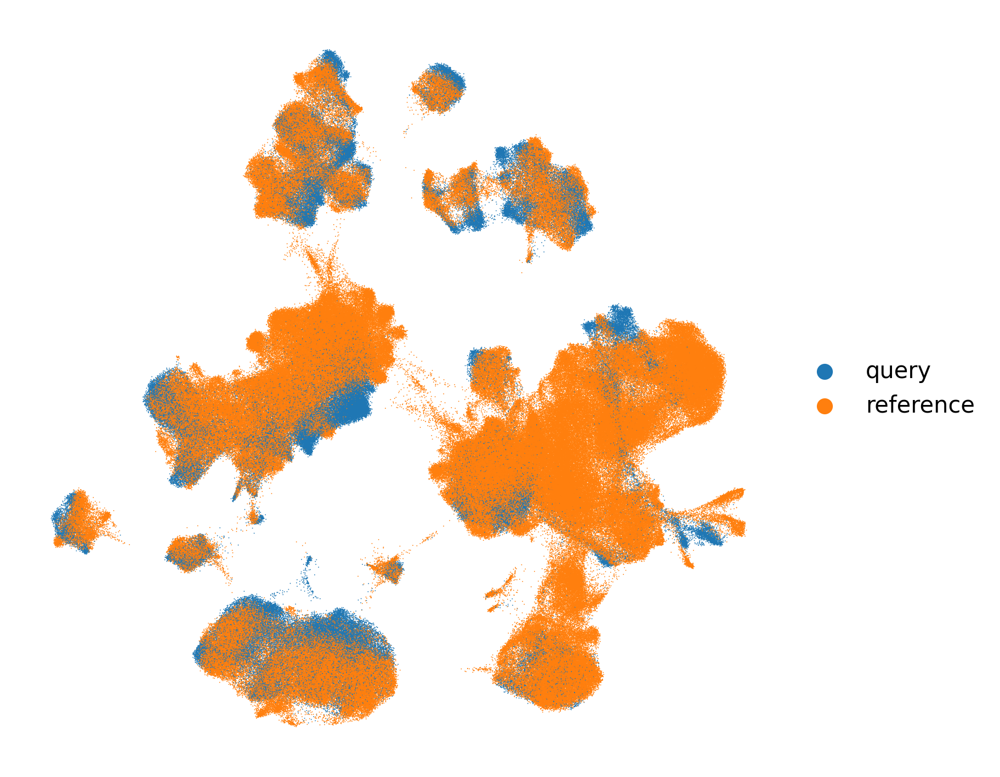

In [164]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="origin", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_healthy_extension_origin.png")

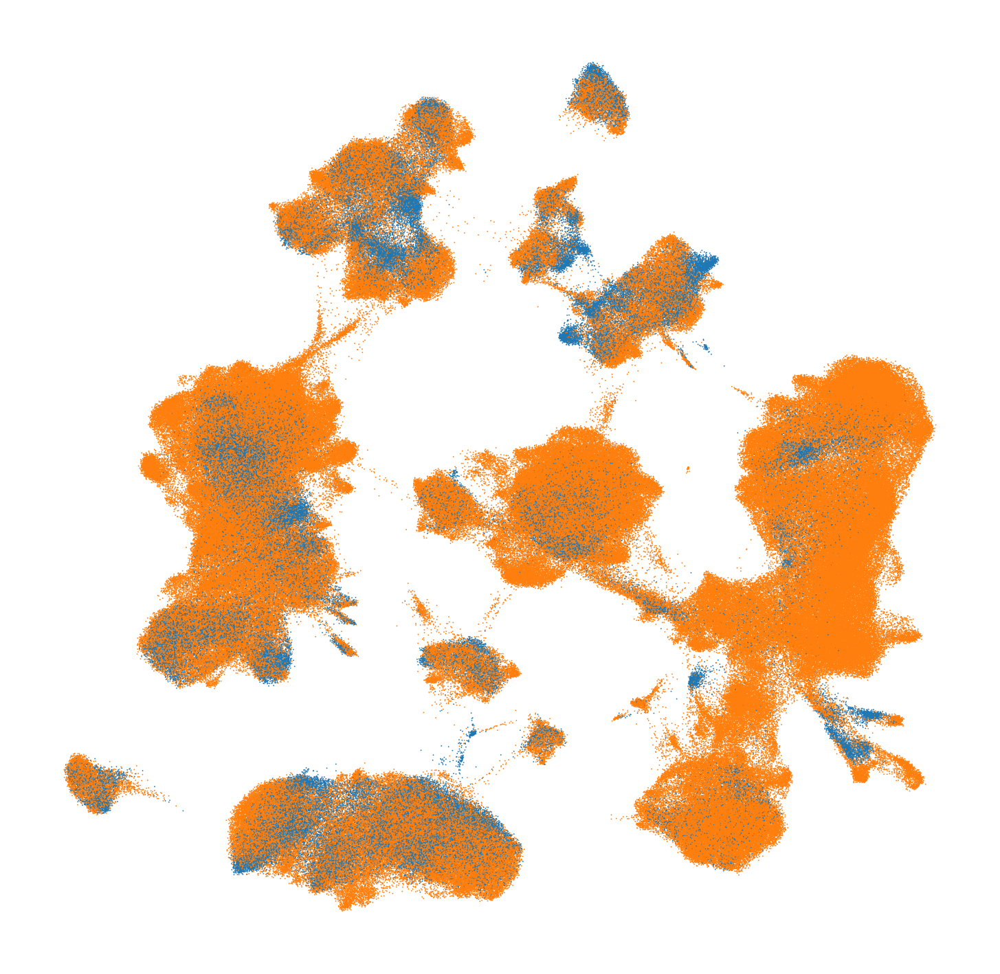

In [165]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="origin", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False, legend_loc=None,
                   title="")
    plt.savefig("figures/scANVI_healthy_extension_origin.png")

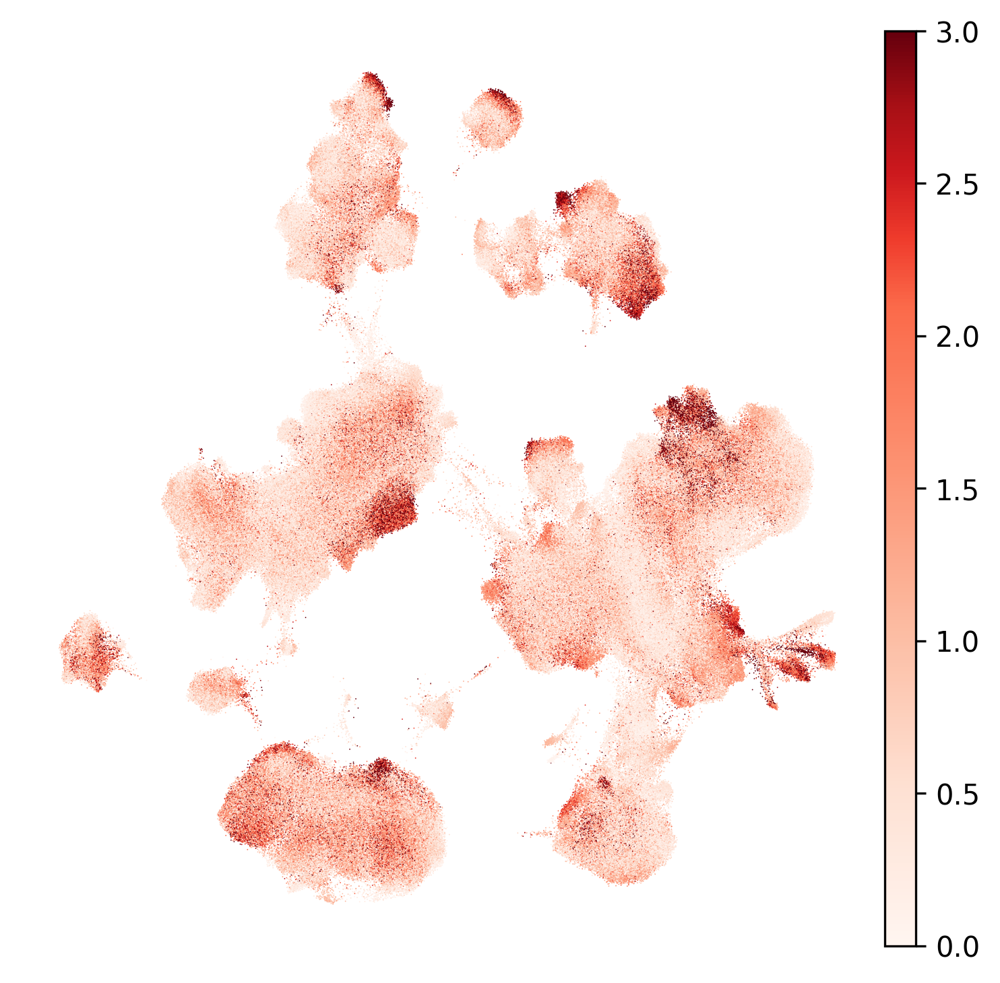

In [159]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="diff_denovo_recalc", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_healthy_extension_milo.png")

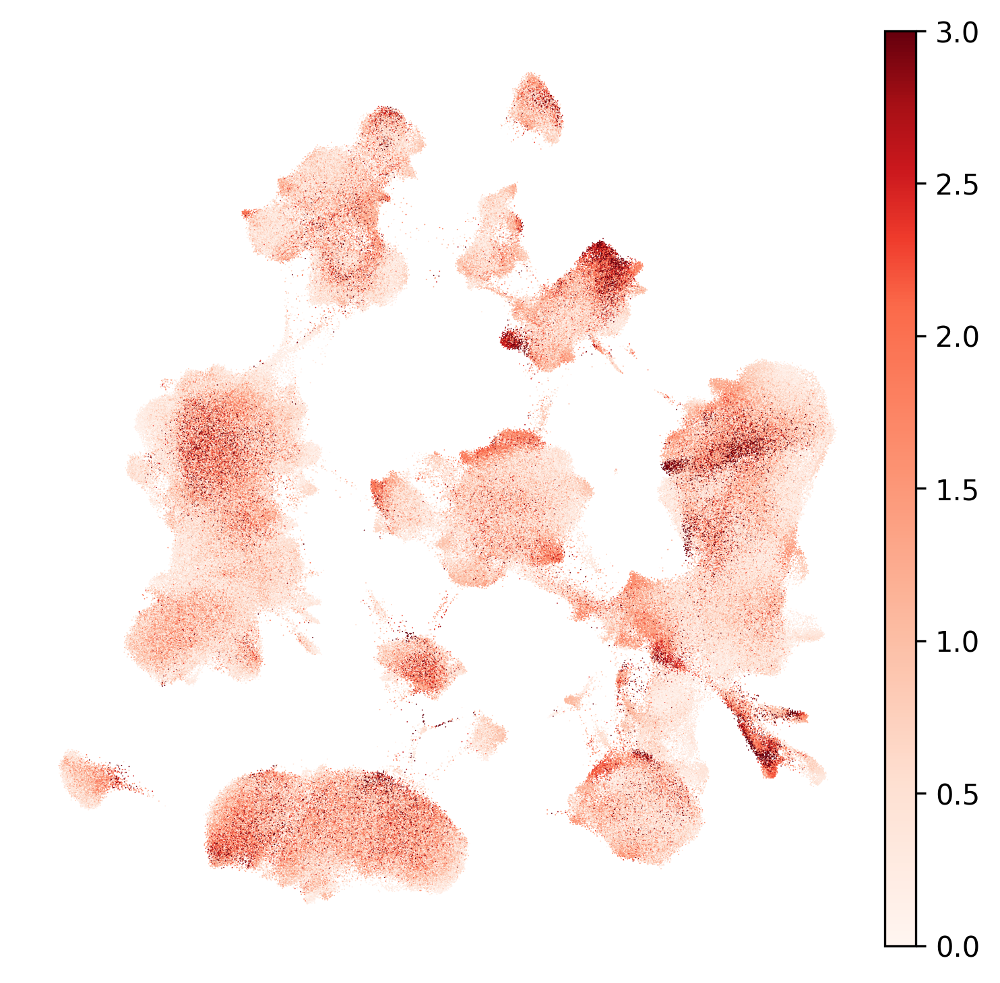

In [160]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="diff_scArches_unlabeled", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    plt.savefig("figures/scANVI_healthy_extension_milo.png")

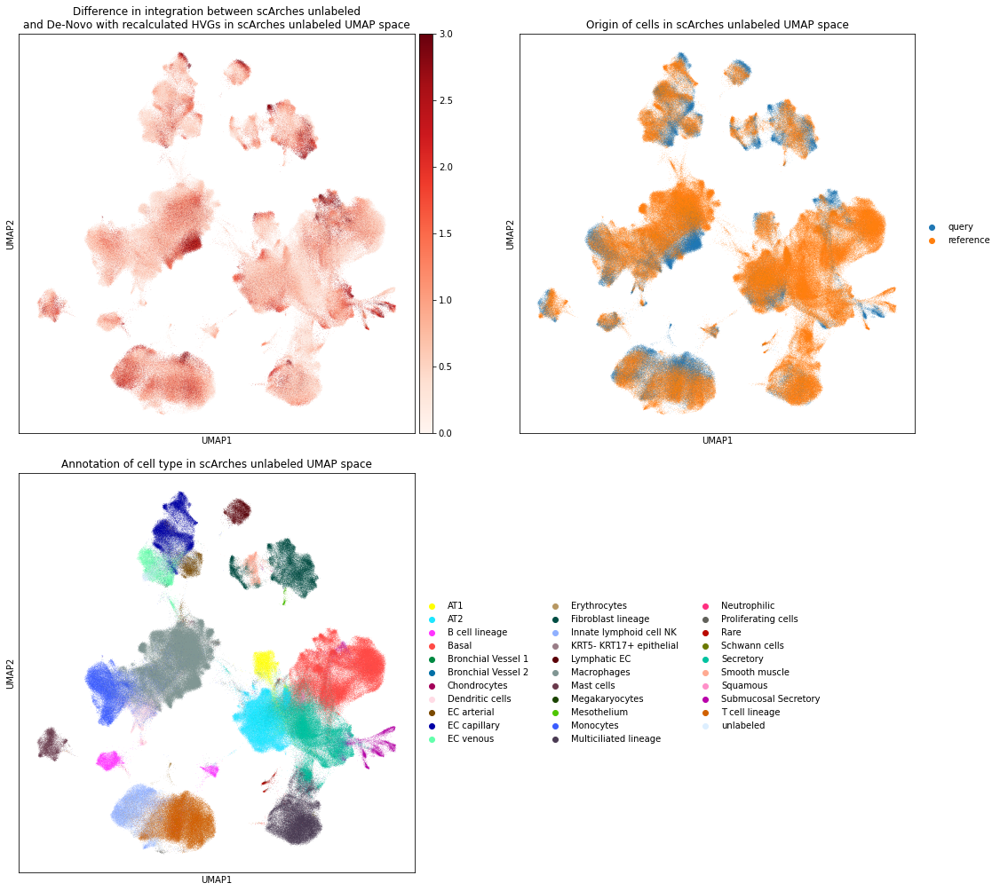

In [ ]:
sc.pl.umap(scarches_unlabeled_plot, color = ["diff_denovo_recalc", "origin", "scanvi_label_original"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save = f"_healthy_scarches_unlabeled_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in scArches unlabeled UMAP space",
                  "Origin of cells in scArches unlabeled UMAP space",
                  "Annotation of cell type in scArches unlabeled UMAP space"])

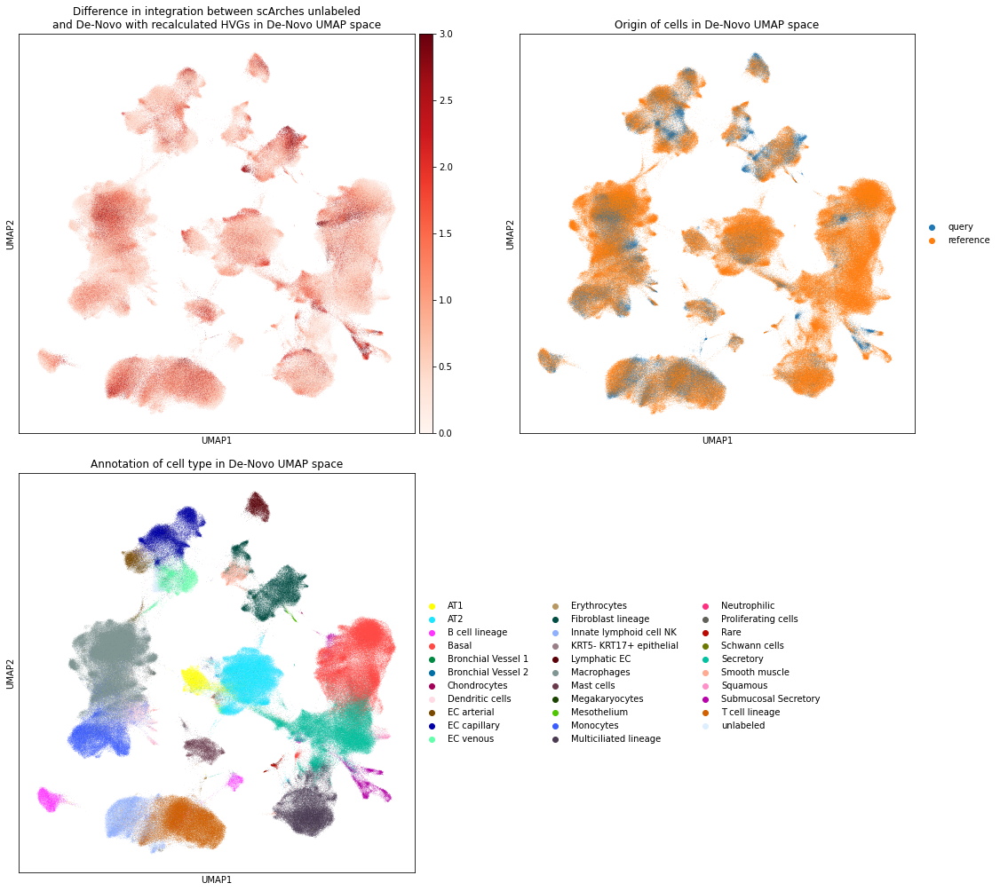

In [22]:
sc.pl.umap(denovo_recalc_plot, color = ["diff_scArches_unlabeled", "origin", "scanvi_label"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save= f"_healthy_denovo_recalc_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in De-Novo UMAP space",
                  "Origin of cells in De-Novo UMAP space",
                  "Annotation of cell type in De-Novo UMAP space"])

### 1.1 Compare with Control Group (scANVI with reference HVGs)

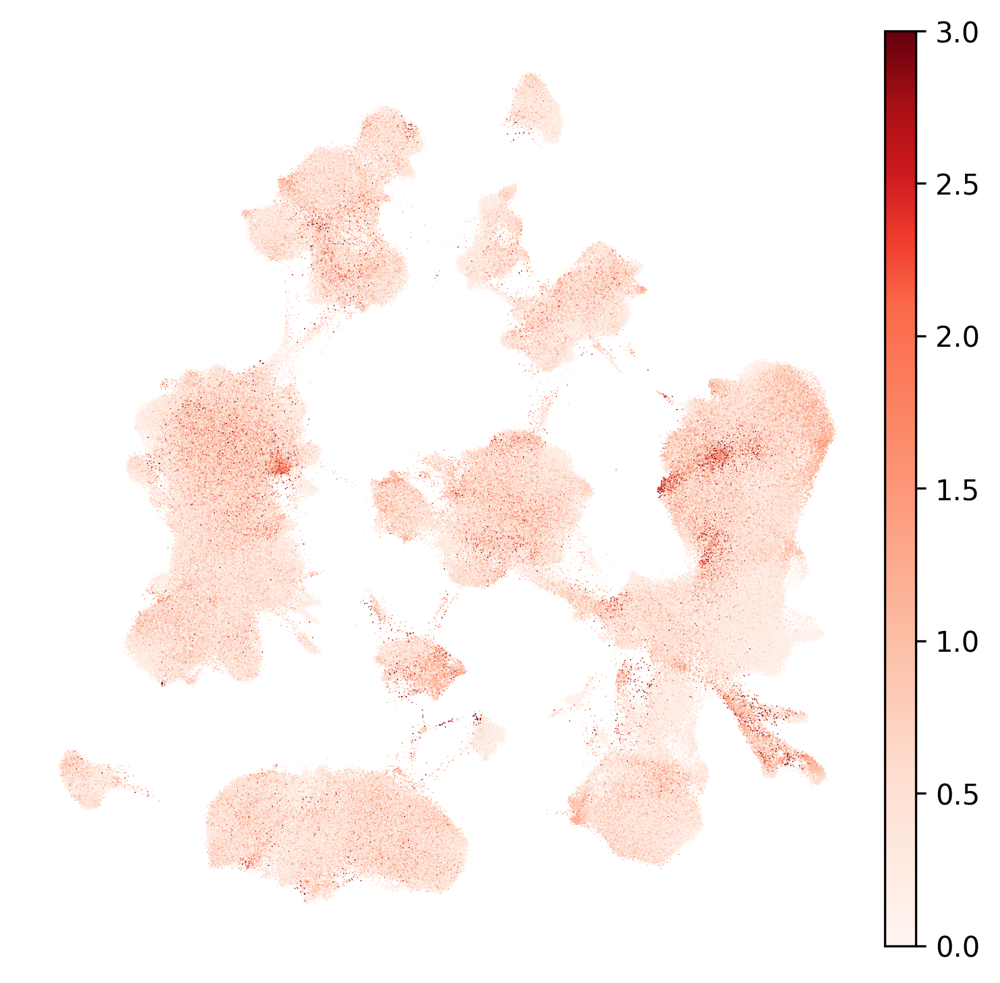

In [78]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="diff_denovo_ref", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/Healthy_control_denovo_recalc_denovo_ref.png")

### 1.2 Compare with Control Group (scArches labeled)

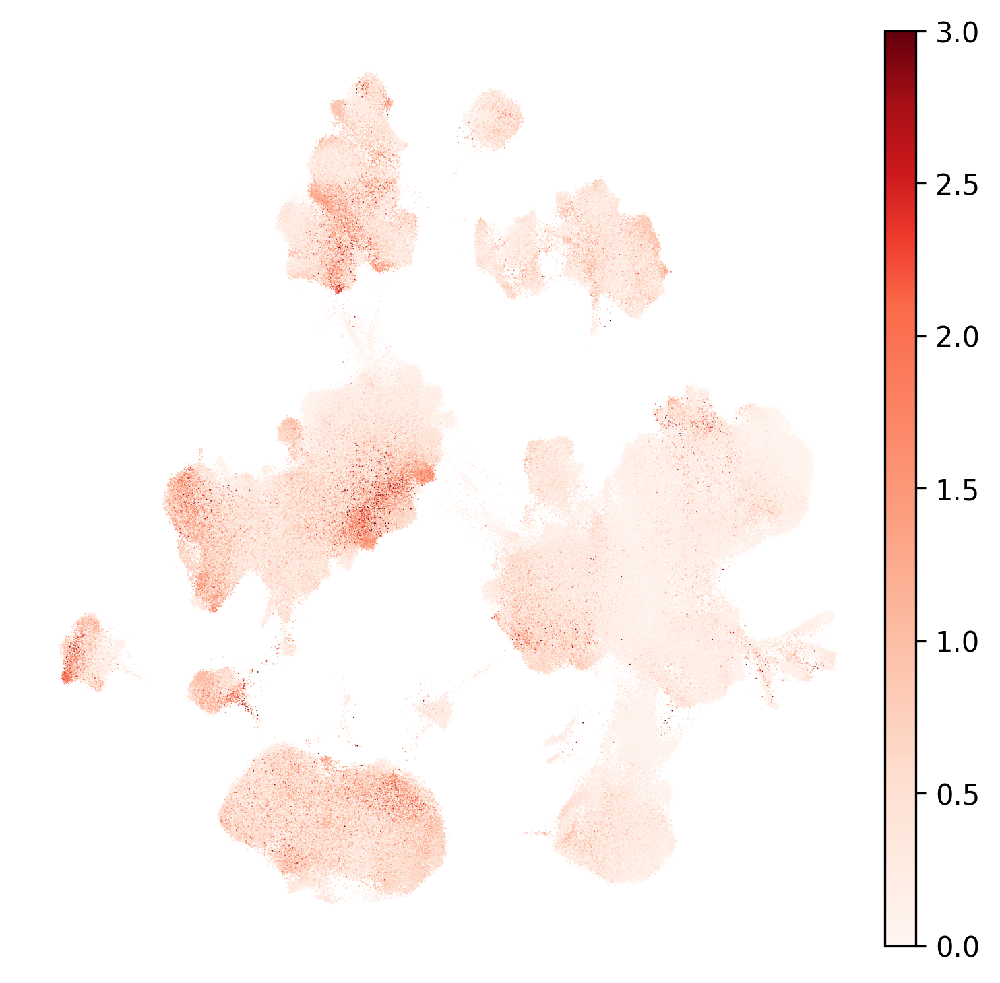

In [79]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="diff_scArches_labeled", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/Healthy_control_scarches_unlabeled_scarches_labeled.png")

### 1.3 Milo Distributions

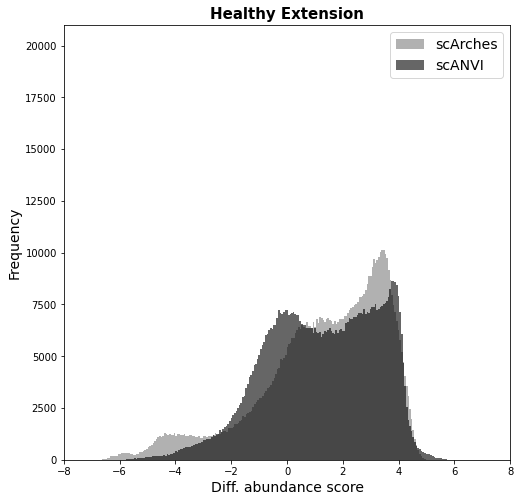

In [14]:
plt.hist(scarches_unlabeled.obs.logFC_avg, bins=200, color = "darkgrey",alpha=0.9, label="scArches")
plt.hist(denovo_recalc.obs.logFC_avg, bins=200, color = "black",alpha=0.6, label="scANVI")
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("Healthy Extension",size=15,fontweight="bold")
plt.xlabel("Diff. abundance score",size=14)
plt.ylabel("Frequency",size=14)
plt.legend(loc='upper right',prop={'size': 14})
plt.grid(False)
plt.savefig("figures/healthy_extension_DA_score_distr.png")

In [27]:
scarches_unlabeled.write("healthy_hist.h5ad")

In [29]:
ipf = sc.read("ipf_hist.h5ad")
nucleus = sc.read("nucleus_hist.h5ad")

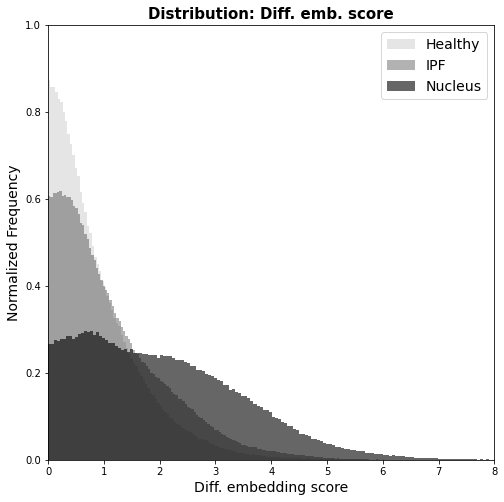

In [53]:
plt.hist(scarches_unlabeled.obs.diff_denovo_recalc, bins=200, color = "darkgrey",alpha=0.3,density=True, label="Healthy")
plt.hist(ipf.obs.diff_denovo_recalc, bins=200, color = "black",alpha=0.3,density=True,label="IPF")
plt.hist(nucleus.obs.diff_denovo_recalc, bins=200, color = "black",alpha=0.6,density=True,label="Nucleus")



plt.ylim(0,1)
plt.xlim(0,8)
plt.title("Distribution: Diff. emb. score",size=15,fontweight="bold")
plt.xlabel("Diff. embedding score",size=14)
plt.ylabel("Normalized Frequency",size=14)
plt.legend(loc='upper right',prop={'size': 14})
plt.grid(False)
plt.savefig("figures/de_score_comparison.png",dpi=300)

# 2. Boxplots

In [39]:
# Sort labels by median of difference of logFC value
labels_sorted = list(scarches_unlabeled.obs.groupby("scanvi_label_original")["diff_denovo_recalc"].median().sort_values().index)

In [40]:
sort_by = [labels_sorted.index(x) for x in sorted(labels_sorted)]

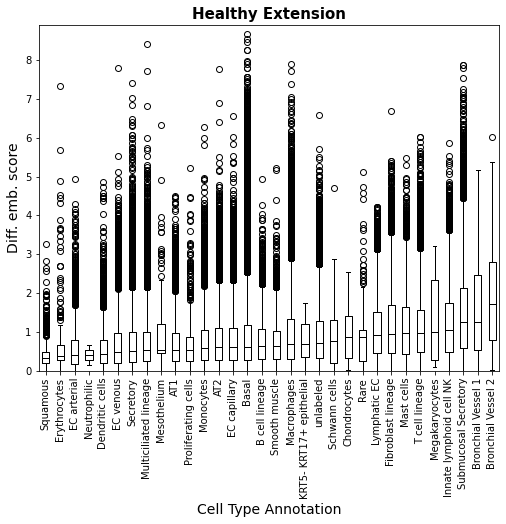

In [41]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc',by='scanvi_label_original', positions=sort_by, 
                               boxprops=dict(color="0"), medianprops=dict(color="0"), whiskerprops=dict(color="0") )
plt.xticks(rotation=90)
plt.title("Healthy Extension",fontweight="bold",size=15)
plt.xlabel("Cell Type Annotation",size=14)
plt.ylabel("Diff. emb. score",size=14)
plt.ylim(0,8.9)
plt.grid(False)
plt.suptitle('')
plt.subplots_adjust(bottom=0.3)
#plt.show()
plt.savefig(f"figures/healthy_boxplot_scanvi_label_{date}.jpg")

In [42]:
#further investigate new, rare, and meaningful cell types
new_labels_lvl3 = ["Erythrocytes", "Schwann myelinating", "Schwann nonmyelinating", "Megakaryocytes"]

rare_labels_lvl3 = ["Rare"]
rare_labels_lvl4 = ["Neuroendocrine"]

immune_labels_lvl4 = ["Regulatory T cells", "Gamma-delta T cells", "ILCs", "NKT cells", "NK cells"]
immune_labels_lvl5 = ["CD4 T cells MAIT", "CD4 T cells naive", "CD4T cells TRM", "CD8 T cells GZMK+", "CD8 T cells ME",
                     "CD8 T cells TRM", "NK_ITGAD+", "NK_XCL1+"]

new_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(new_labels_lvl3)]
new_lvl3.obs["diff_denovo_recalc_abs"] = abs(new_lvl3.obs.diff_denovo_recalc)

rare_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(rare_labels_lvl3)]
rare_lvl3.obs["diff_denovo_recalc_abs"] = abs(rare_lvl3.obs.diff_denovo_recalc)
rare_lvl4 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_4"].isin(rare_labels_lvl4)]
rare_lvl4.obs["diff_denovo_recalc_abs"] = abs(rare_lvl4.obs.diff_denovo_recalc)

immune_lvl4 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_4"].isin(immune_labels_lvl4)]
immune_lvl4.obs["diff_denovo_recalc_abs"] = abs(immune_lvl4.obs.diff_denovo_recalc)
immune_lvl5 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_5"].isin(immune_labels_lvl5)]
immune_lvl5.obs["diff_denovo_recalc_abs"] = abs(immune_lvl5.obs.diff_denovo_recalc)

Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.


In [46]:
labels_sorted_lvl3 = list(new_lvl3.obs.groupby("ann_level_3")["diff_denovo_recalc_abs"].median().sort_values().index)
labels_sorted_lvl4 = list(immune_lvl4.obs.groupby("ann_level_4")["diff_denovo_recalc_abs"].median().sort_values().index)
labels_sorted_lvl5 = list(immune_lvl5.obs.groupby("ann_level_5")["diff_denovo_recalc_abs"].median().sort_values().index)

In [47]:
sort_by_lvl3 = [labels_sorted_lvl3.index(x) for x in sorted(labels_sorted_lvl3)]
sort_by_lvl4 = [labels_sorted_lvl4.index(x) for x in sorted(labels_sorted_lvl4)]
sort_by_lvl5 = [labels_sorted_lvl5.index(x) for x in sorted(labels_sorted_lvl5)]

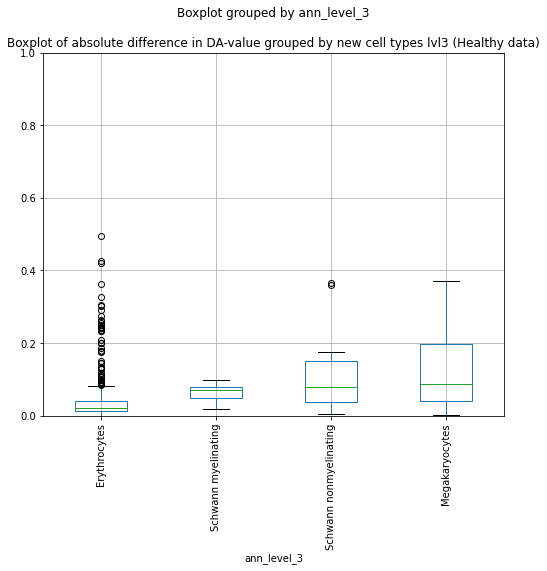

In [48]:
new_lvl3.obs.boxplot(column='diff_denovo_recalc',by='ann_level_3', positions=sort_by_lvl3)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by new cell types lvl3 (Healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/healthy_boxplot_new_lvl3_{date}.jpg")

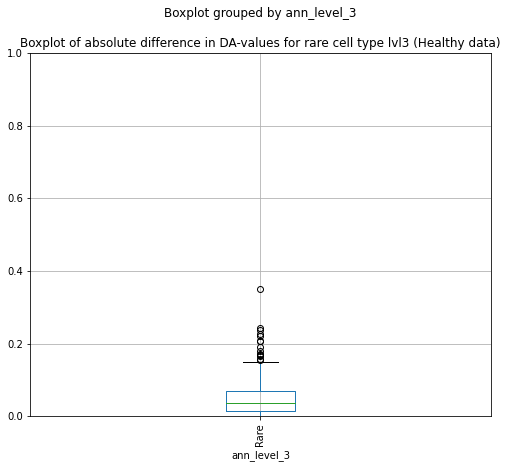

In [50]:
rare_lvl3.obs.boxplot(column='diff_denovo_recalc',by='ann_level_3')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for rare cell type lvl3 (Healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/healthy_boxplot_rare_lvl3_{date}.jpg")

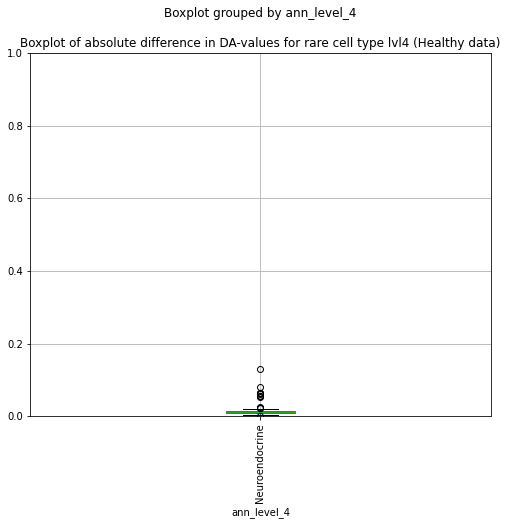

In [51]:
rare_lvl4.obs.boxplot(column='diff_denovo_recalc',by='ann_level_4')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for rare cell type lvl4 (Healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/healthy_boxplot_rare_lvl4_{date}.jpg")

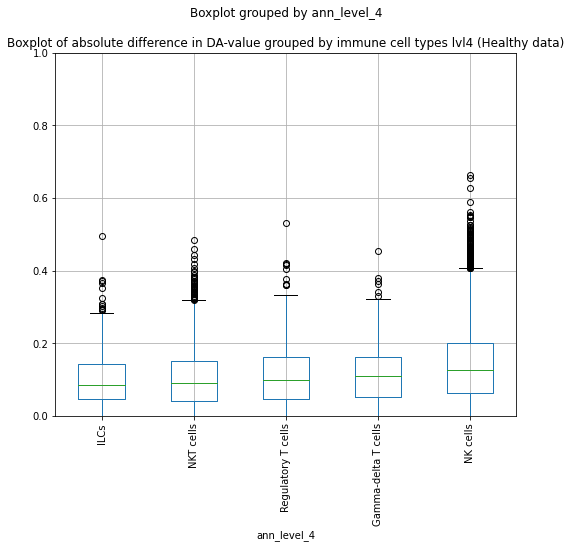

In [52]:
immune_lvl4.obs.boxplot(column='diff_denovo_recalc',by='ann_level_4', positions=sort_by_lvl4)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by immune cell types lvl4 (Healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/healthy_boxplot_immune_lvl4_{date}.jpg")

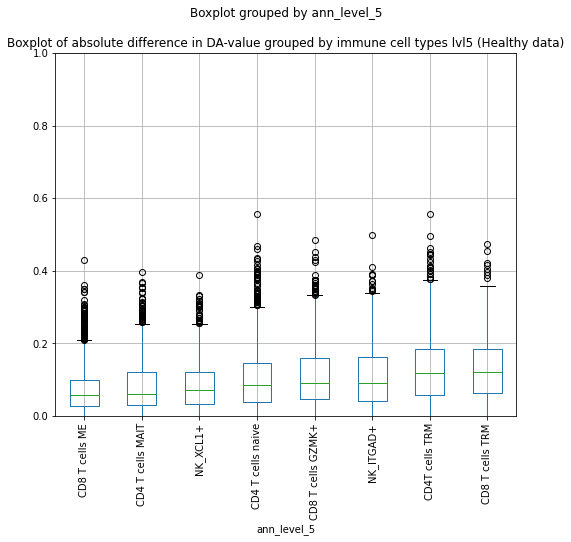

In [53]:
immune_lvl5.obs.boxplot(column='diff_denovo_recalc',by='ann_level_5', positions=sort_by_lvl5)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by immune cell types lvl5 (Healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/healthy_boxplot_immune_lvl5_{date}.jpg")

# 3. Clustering analysis and DE testing

### Get original data with raw counts for all genes for differential expression testing

In [66]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/Meyer_2021_norm.h5ad")
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v5.h5ad")
source_adata.var = source_adata.var.set_index("gene_ids")
combined_data = source_adata.concatenate(query_data, join="outer")
combined_data.X = np.nan_to_num(combined_data.X, copy=False)
combined_data.X = combined_data.layers["counts"].copy()

In [42]:
sc.tl.leiden(scarches_unlabeled, resolution= 0.3)

running Leiden clustering
    finished: found 17 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:12:24)


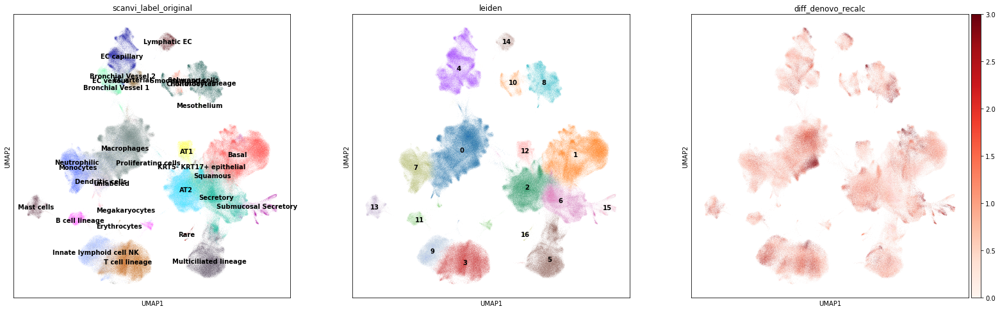

In [43]:
sc.pl.umap(scarches_unlabeled, color=["scanvi_label_original","leiden","diff_denovo_recalc"], legend_loc="on data",vmin=0,vmax=3,cmap = "Reds")

## 3.1 Investigate Lympathic EC cluster

In [44]:
subset_lymp_ec = scarches_unlabeled[(scarches_unlabeled.obs.leiden == "14")].copy()

In [45]:
sc.pp.neighbors(subset_lymp_ec, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(subset_lymp_ec)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:13)


In [57]:
sc.tl.leiden(subset_lymp_ec, resolution= 0.38,key_added = "leiden_sub")

running Leiden clustering
    finished: found 5 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:00:01)


In [ ]:
sc.pl.umap(subset_lymp_ec, color=["leiden_sub", "origin", "diff_denovo_recalc"],size=20,ncols=2,wspace=0.15,vmin=0,vmax=3, cmap="Reds")

In [59]:
subset_lymp_ec.obs.loc[subset_lymp_ec.obs.leiden_sub!="0","leiden_sub"] = "1"

In [68]:
#Get leiden cluster assignment for macrophages
combined_data.obs["leiden_lymph_scarches"] = pd.merge(combined_data.obs,subset_lymp_ec.obs.leiden_sub, how="left", left_index=True, right_index=True).leiden_sub

In [69]:
combined_data_lymph = combined_data[~pd.isna(combined_data.obs.leiden_lymph_scarches)]

In [ ]:
# normalize 
combined_data_lymph_norm = scib_excerpts.SCRAN_normalize(combined_data_lymph, log_transform=False)

In [71]:
combined_data_lymph_norm.var.index = combined_data_lymph_norm.var["gene_symbols-0"]

In [72]:
#get unique index
combined_data_lymph_norm_u = combined_data_lymph_norm[:, ~combined_data_lymph_norm.var.index.duplicated(keep ='first')]

In [73]:
combined_data_lymph_norm_u.obs = pd.merge(combined_data_lymph_norm_u.obs,subset_lymp_ec.obs[["scanvi_label_original","origin", 'logFC_avg', 'diff_denovo_recalc', 'diff_denovo_ref', 'diff_scArches_labeled', 'leiden_sub']], how="left", left_index=True, right_index=True)

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [75]:
combined_data_lymph_norm_u.obsm["X_scArches"] = subset_lymp_ec.obsm["X_scArches"]

In [76]:
combined_data_lymph_norm_u.var_names.name = "index"

In [79]:
combined_data_lymph_norm_u.obs["age"] = combined_data_lymph_norm_u.obs["age"].astype(str)
combined_data_lymph_norm_u.var["highly_variable-0"] = combined_data_lymph_norm_u.var["highly_variable-0"].astype(str)
combined_data_lymph_norm_u.var["highly_variable_intersection-0"] = combined_data_lymph_norm_u.var["highly_variable_intersection-0"].astype(str)

In [80]:
combined_data_lymph_norm_u.write("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/healthy_original_count_data_norm_lymph_u.h5ad")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'age' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'highly_variable-0' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a n

In [4]:
combined_data_lymph_norm_u = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/healthy_original_count_data_norm_lymph_u.h5ad")

In [ ]:
sc.pp.neighbors(combined_data_lymph_norm_u, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(combined_data_lymph_norm_u)

computing neighbors


2022-03-07 15:21:18.491368: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-03-07 15:21:18.491400: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:09)
computing UMAP





In [32]:
sc.set_figure_params(scanpy=True, fontsize=16,dpi=300,dpi_save=300,figsize=(6,6))
sc.pl.umap(combined_data_lymph_norm_u, color=["leiden_lymph_scarches", "origin","diff_denovo_recalc"],size=45, 
          palette=colordict, frameon=False, vmin=0,vmax=3,cmap=new_reds, title=["Leiden Clustering","Origin",r"$\Delta_{logFC}$"],wspace=0.2,
           legend_fontsize=14,
          save = "_healthy_lymph_ec.png"
          )


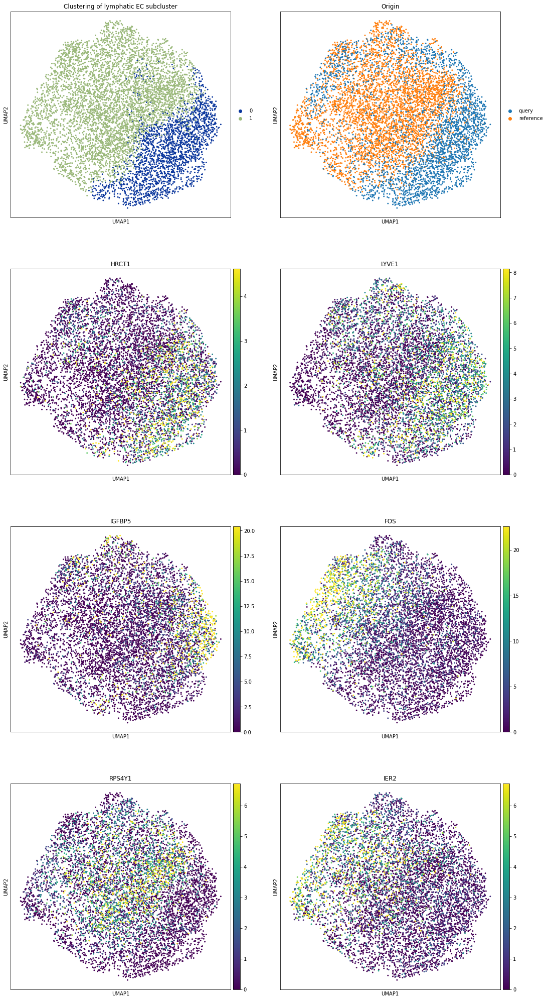

In [54]:
sc.pl.umap(combined_data_lymph_norm_u, color=["leiden_lymph_scarches", "origin","HRCT1","LYVE1","IGFBP5","FOS","RPS4Y1","IER2"],size=35, 
          title = ["Clustering of lymphatic EC subcluster", "Origin"],  palette=colordict, ncols=2, vmin=0,vmax="p95"
          #,save = "_healthy_lymph_ec_top_de_genes.png"
          )

ranking genes
    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


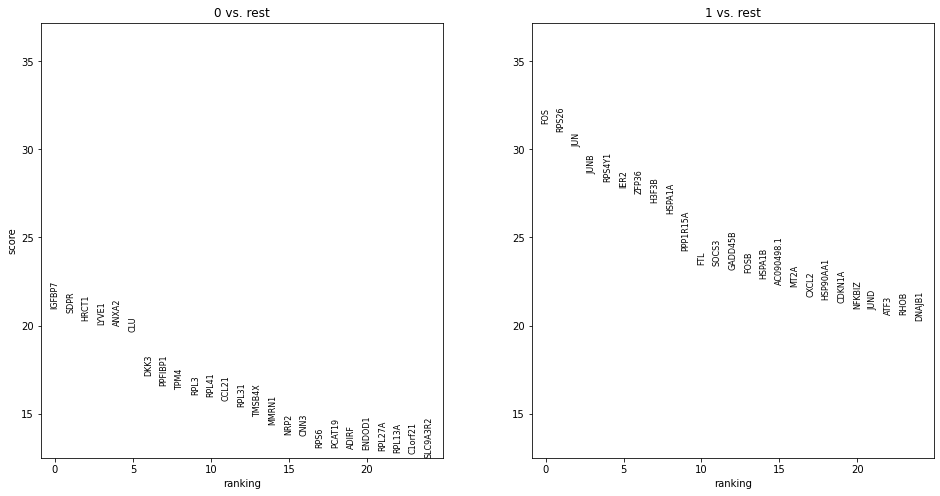

In [6]:
sc.tl.rank_genes_groups(combined_data_lymph_norm_u, groupby='leiden_lymph_scarches', method='t-test', key_added = "t-test", use_raw=False)
sc.pl.rank_genes_groups(combined_data_lymph_norm_u, n_genes=25, key = "t-test", use_raw = False)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 2, max_out_group_fraction: 0.5


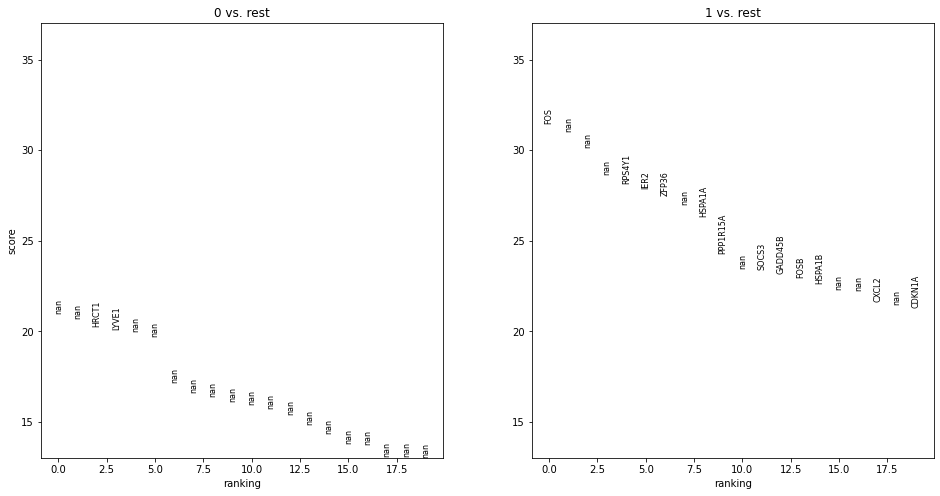

In [7]:
sc.tl.filter_rank_genes_groups(combined_data_lymph_norm_u, min_fold_change=2, key="t-test", use_raw=False)
# visualize results
sc.pl.rank_genes_groups(combined_data_lymph_norm_u, key='rank_genes_groups_filtered', use_raw = False)

In [57]:
table_de = sc.get.rank_genes_groups_df(combined_data_lymph_norm_u, key='rank_genes_groups_filtered', group = None)

In [58]:
table_de = table_de[~pd.isna(table_de.names)]

In [89]:
pd.concat([table_de[table_de.group=="0"].head(100), table_de[table_de.group=="1"].head(100)]).to_csv("/storage/groups/ml01/workspace/jan.domke/Data/healthy_lymph_ec_top_100_de_genes_per_group.csv")

In [ ]:
sc.set_figure_params(scanpy=True, fontsize=16,dpi=300,dpi_save=300,figsize=(6,6))
sc.pl.umap(combined_data_lymph_norm_u, color=["leiden_lymph_scarches", "origin","diff_denovo_recalc"],size=45, 
          palette=colordict, frameon=False, vmin=0,vmax=3,cmap=new_reds, title=["Leiden Clustering","Origin",r"$\Delta_{logFC}$"],wspace=0.2,
           legend_fontsize=14,
          save = "_healthy_lymph_ec.png"
          )


In [ ]:
# visualize results using dotplot
sc.pl.rank_genes_groups_dotplot(combined_data_lymph_norm_u, n_genes=7, key='rank_genes_groups_filtered',  gene_symbols = "gene_symbols-0"
                               ,save="healthy_lymph_ec_dotplot_de_genes.png")

## 3.2 Investigate Macrophages cluster

In [101]:
subset_macro = scarches_unlabeled[(scarches_unlabeled.obs.leiden == "0")].copy()

In [102]:
sc.pp.neighbors(subset_macro, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:58)


In [103]:
sc.tl.umap(subset_macro)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:03:17)


In [104]:
subset_macro.obs.manual_ann = subset_macro.obs.manual_ann.astype("str")

In [105]:
subset_macro.obs.ann_level_5  = subset_macro.obs.ann_level_5.astype(str)
subset_macro.obs.original_ann_level_5  = subset_macro.obs.original_ann_level_5.astype(str)

In [106]:
subset_macro.obs["combined_ann"] = subset_macro.obs.manual_ann.astype(str)
subset_macro.obs.loc[subset_macro.obs.study == "Meyer_2021","combined_ann"] = subset_macro.obs[subset_macro.obs.study=="Meyer_2021"].ann_level_4

In [24]:
sc.tl.leiden(subset_macro, resolution= 0.38,key_added = "leiden_sub")

running Leiden clustering
    finished: found 12 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:02:46)


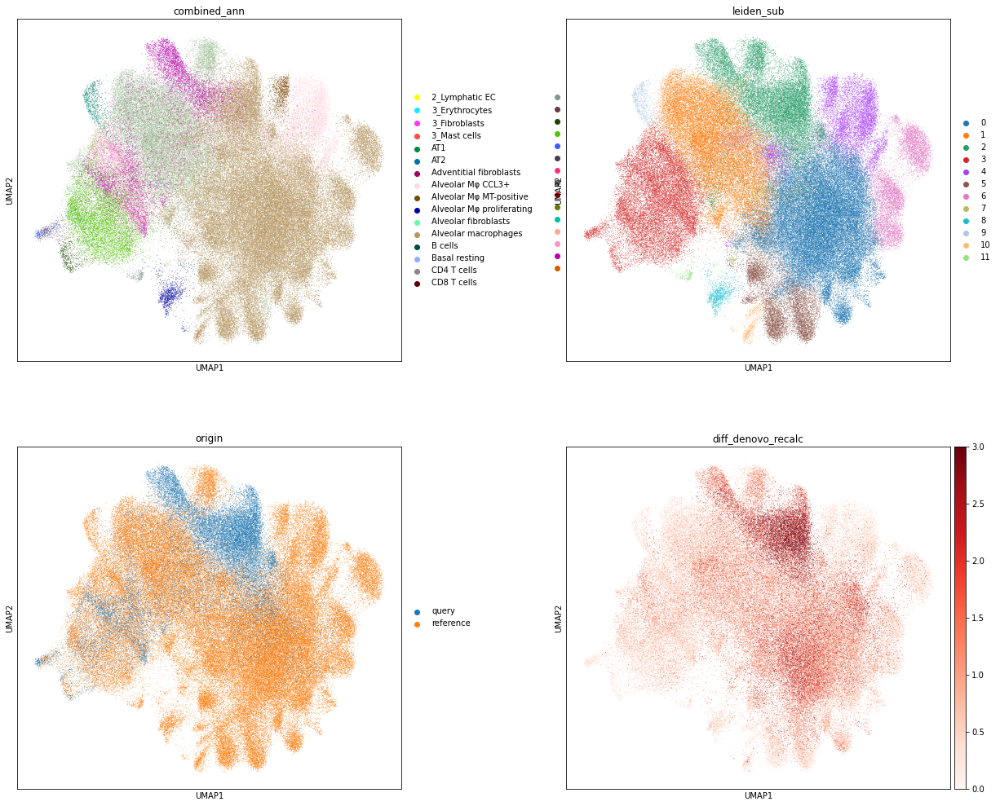

In [25]:
sc.pl.umap(subset_macro, color=["combined_ann","leiden_sub", "origin", "diff_denovo_recalc"],size=2,ncols=2,wspace=0.3,vmin=0,vmax=3, cmap="Reds")

In [26]:
subset_macro.obs.loc[subset_macro.obs.leiden_sub!="2","leiden_sub"] = "1"

In [34]:
#Get leiden cluster assignment for macrophages
combined_data.obs["leiden_macro_scarches"] = pd.merge(combined_data.obs,subset_macro.obs.leiden_sub, how="left", left_index=True, right_index=True).leiden_sub

In [35]:
combined_data_macro = combined_data[~pd.isna(combined_data.obs.leiden_macro_scarches)]

In [ ]:
# normalize 
combined_data_macro_norm = scib_excerpts.SCRAN_normalize(combined_data_macro, log_transform=False)

In [39]:
combined_data_macro_norm.var.index = combined_data_macro_norm.var["gene_symbols-0"]

In [40]:
combined_data_macro_norm_u = combined_data_macro_norm[:, ~combined_data_macro_norm.var.index.duplicated(keep ='first')]

In [42]:
combined_data_macro_norm_u.obs = pd.merge(combined_data_macro_norm_u.obs,subset_macro.obs[["scanvi_label_original","origin", 'logFC_avg', 'diff_denovo_recalc', 'diff_denovo_ref', 'diff_scArches_labeled', 'leiden_sub']], how="left", left_index=True, right_index=True)

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [43]:
combined_data_macro_norm_u.obsm["X_scArches"] = subset_macro.obsm["X_scArches"]

In [44]:
combined_data_macro_norm_u.var_names.name = "index"

In [49]:
combined_data_macro_norm_u.obs["age"] = combined_data_macro_norm_u.obs["age"].astype(str)
combined_data_macro_norm_u.var["highly_variable-0"] = combined_data_macro_norm_u.var["highly_variable-0"].astype(str)
combined_data_macro_norm_u.var["highly_variable_intersection-0"] = combined_data_macro_norm_u.var["highly_variable_intersection-0"].astype(str)

In [50]:
combined_data_macro_norm_u.write("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/healthy_original_count_data_norm_macro_u.h5ad")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'age' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'highly_variable-0' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a n

### DE Analysis Macrophages I

In [14]:
combined_data_macro_norm_u = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/healthy_original_count_data_norm_macro_u.h5ad")

In [15]:
sc.pp.neighbors(combined_data_macro_norm_u, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(combined_data_macro_norm_u)

computing neighbors


2022-03-09 13:34:25.953370: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-03-09 13:34:25.953399: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:10)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:03:06)


In [16]:
sc.tl.leiden(combined_data_macro_norm_u, resolution= 0.38, key_added = "leiden_macro_plot")

running Leiden clustering
    finished: found 12 clusters and added
    'leiden_macro_plot', the cluster labels (adata.obs, categorical) (0:01:56)


In [17]:
combined_data_macro_norm_u.obs.loc[(combined_data_macro_norm_u.obs.leiden_macro_plot=="7") | 
                                   (combined_data_macro_norm_u.obs.leiden_macro_plot=="8") |
                                   (combined_data_macro_norm_u.obs.leiden_macro_plot=="10") |
                                   (combined_data_macro_norm_u.obs.leiden_macro_plot=="11") ,"leiden_macro_plot"] = "5"
combined_data_macro_norm_u.obs.loc[(combined_data_macro_norm_u.obs.leiden_macro_plot=="9") ,"leiden_macro_plot"] = "7"

In [18]:
combined_data_macro_norm_u.obs["leiden_macro_plot"] = combined_data_macro_norm_u.obs.leiden_macro_plot.cat.remove_unused_categories()

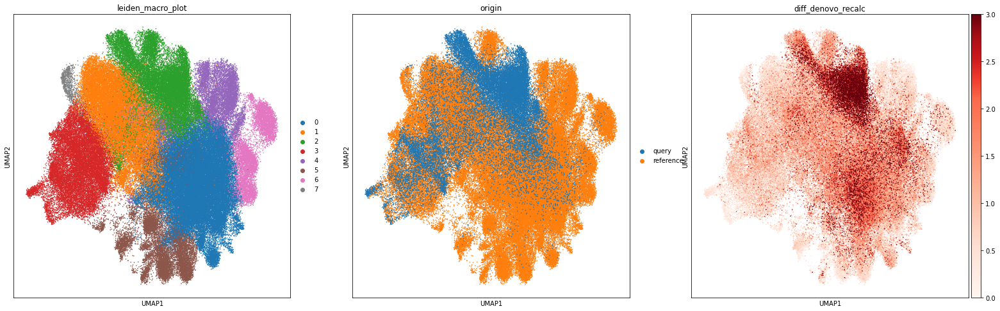

In [19]:
sc.pl.umap(combined_data_macro_norm_u, color=["leiden_macro_plot","origin","diff_denovo_recalc"], vmin=0,vmax=3, cmap=new_reds, size=10
           
          )

In [19]:
sc.tl.rank_genes_groups(combined_data_macro_norm_u, groupby='leiden_macro_plot', method='t-test', key_added = "t-test_plot", use_raw=False)

ranking genes
    finished: added to `.uns['t-test_plot']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:19)


/opt/python/lib/python3.8/site-packages/scanpy/tools/_rank_genes_groups.py:417: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (


In [20]:
sc.tl.filter_rank_genes_groups(combined_data_macro_norm_u, min_fold_change=2, key="t-test_plot", key_added = "rank_genes_groups_filtered_plot", use_raw=False)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 2, max_out_group_fraction: 0.5


In [21]:
table_de_plot = sc.get.rank_genes_groups_df(combined_data_macro_norm_u, key='rank_genes_groups_filtered_plot', group = None)

In [22]:
table_de_plot = table_de_plot[~pd.isna(table_de_plot.names)]

In [23]:
de_genes = table_de_plot[table_de_plot.group=="2"].head(10).names

In [24]:
other_genes = combined_data_macro_norm_u.obs.groupby("ann_level_4").study.count()[combined_data_macro_norm_u.obs.groupby("ann_level_4").study.count()<20].index

In [25]:
combined_data_macro_norm_u.obs["plot_de_genes_cat"] = combined_data_macro_norm_u.obs.ann_level_4.astype(str)
combined_data_macro_norm_u.obs.loc[combined_data_macro_norm_u.obs.leiden_macro_plot=="2","plot_de_genes_cat"] = "Query cluster"
combined_data_macro_norm_u.obs.loc[combined_data_macro_norm_u.obs.ann_level_4.isin(other_genes),"plot_de_genes_cat"] = "Others"

In [26]:
combined_data_macro_norm_u.obs["plot_de_genes_cat"] = combined_data_macro_norm_u.obs.plot_de_genes_cat.astype("category").cat.remove_unused_categories()

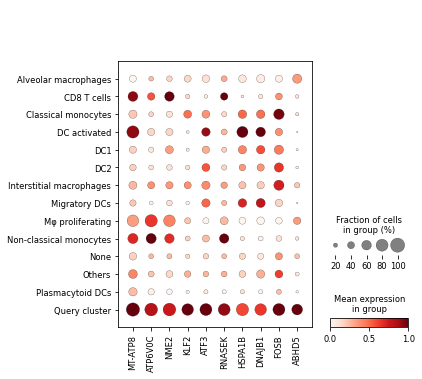

In [30]:
sc.pl.dotplot(combined_data_macro_norm_u, de_genes, groupby='plot_de_genes_cat',standard_scale='var',save="healhty_macro_de_genes_cell_types.png")

### DE Analysis Macrophages II

In [27]:
combined_data_macro_norm_u.obs["leiden_macro_scarches"] = combined_data_macro_norm_u.obs["leiden_macro_plot"].map(
    {"0":"0","1":"0","2":"1","3":"0","4":"0","5":"0","6":"0","7":"0"})
combined_data_macro_norm_u.obs["leiden_macro_scarches"] = combined_data_macro_norm_u.obs.leiden_macro_scarches.astype("category").cat.remove_unused_categories()

In [28]:
combined_data_macro_norm_u_plot =sc.pp.subsample(combined_data_macro_norm_u, fraction=1.,copy=True)

In [29]:
sc.tl.rank_genes_groups(combined_data_macro_norm_u, groupby='leiden_macro_scarches', method='t-test', key_added = "t-test", use_raw=False)
sc.tl.filter_rank_genes_groups(combined_data_macro_norm_u, min_fold_change=2, key="t-test", key_added = "rank_genes_groups_filtered", use_raw=False)
table_de = sc.get.rank_genes_groups_df(combined_data_macro_norm_u, key='rank_genes_groups_filtered', group = None)
table_de = table_de[~pd.isna(table_de.names)]

ranking genes
    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:09)
Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 2, max_out_group_fraction: 0.5


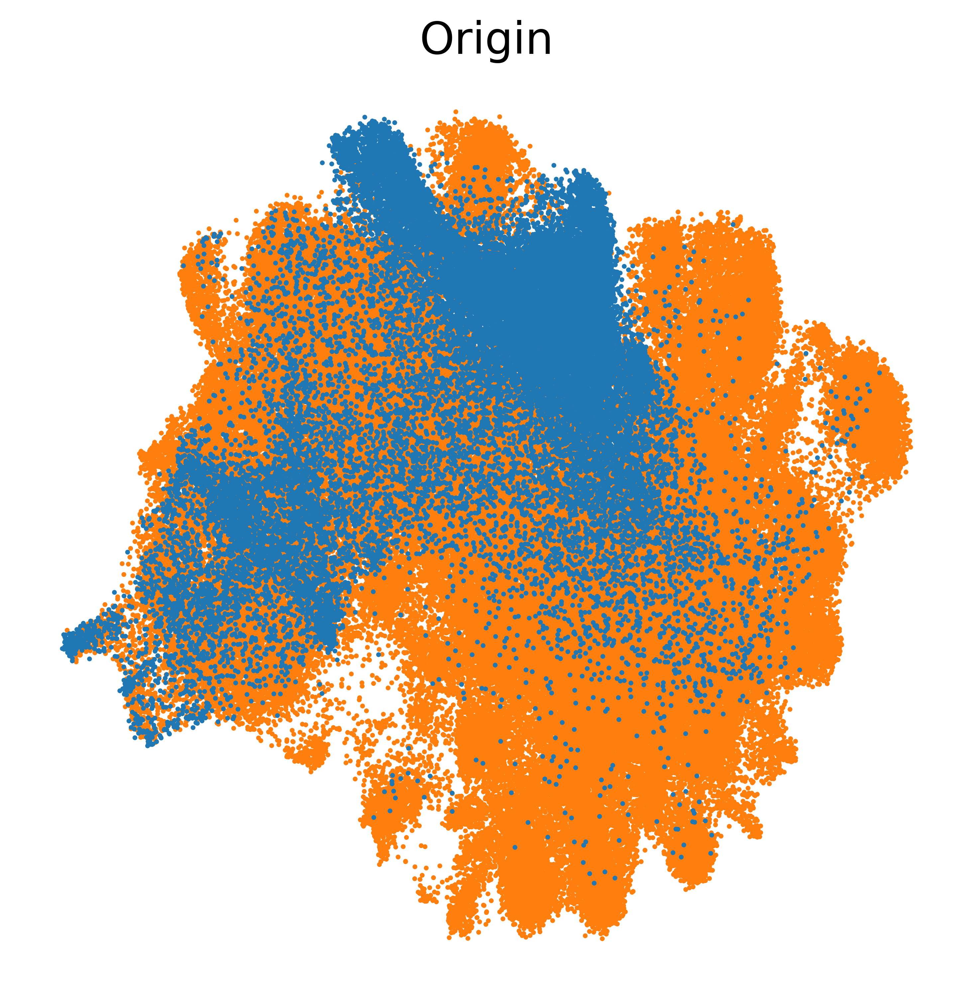

In [31]:
sc.set_figure_params(scanpy=True, fontsize=16,dpi=300,dpi_save=300,figsize=(6,6))
sc.pl.umap(combined_data_macro_norm_u_plot, color=["origin"],size=12,
          title = ["Origin"],frameon=False, legend_fontsize=14,vmin=0,vmax=3, cmap=new_reds, palette=colordict, legend_loc=False,
           save="_healthy_macro_origin.png"
          )

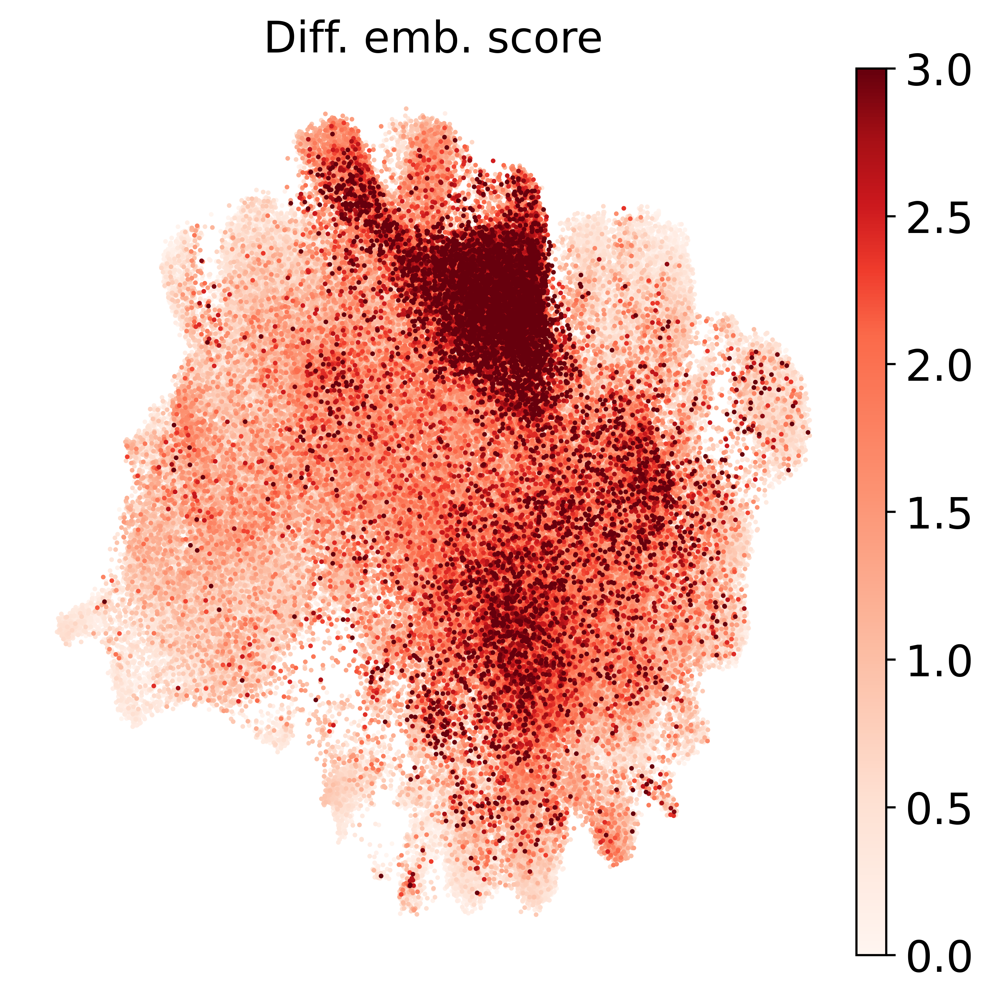

In [33]:
sc.set_figure_params(scanpy=True, fontsize=16,dpi=300,dpi_save=300,figsize=(6,6))
sc.pl.umap(combined_data_macro_norm_u_plot, color=["diff_denovo_recalc"],size=12,
          title = ["Diff. emb. score"],frameon=False, legend_fontsize=14,vmin=0,vmax=3, cmap=new_reds,
           save="_healthy_macro_diff_logFC.png"
          )

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


the obs value 'subject_ID' has more than 103 categories. Uniform 'grey' color will be used for all categories.


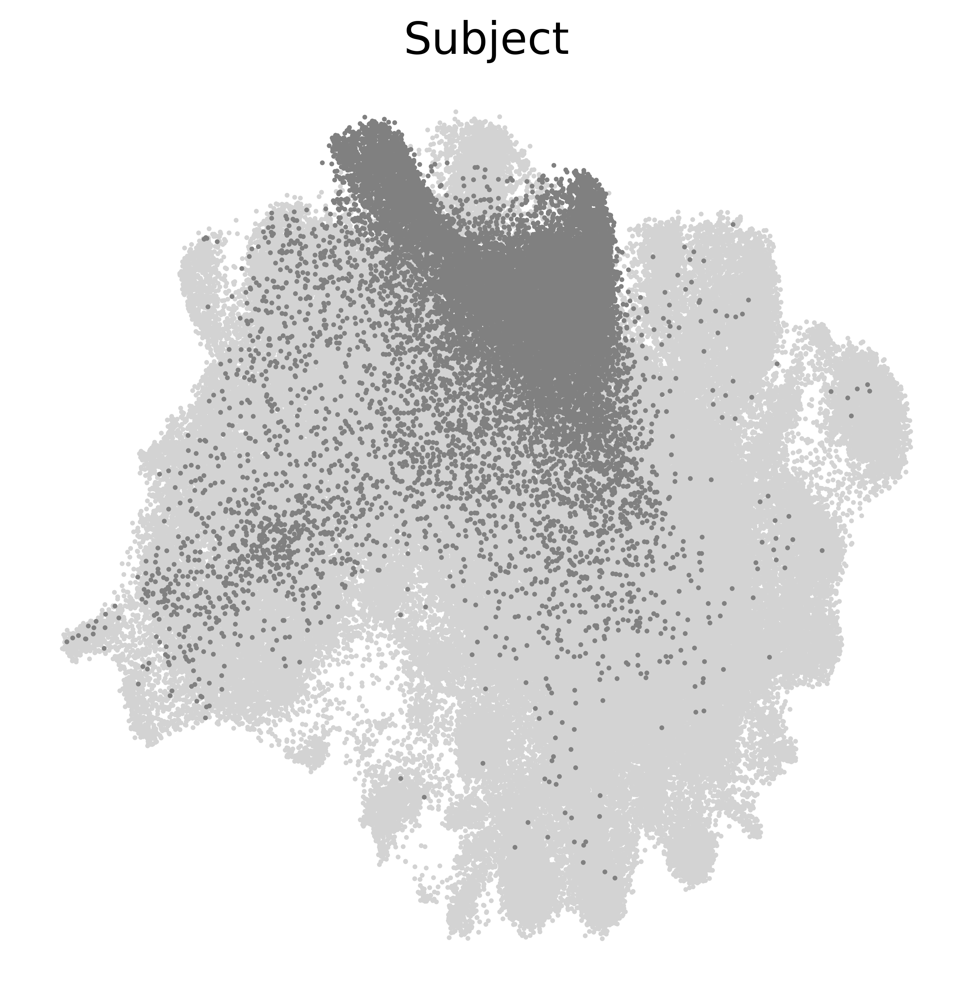

In [34]:
sc.set_figure_params(scanpy=True, fontsize=16,dpi=300,dpi_save=300,figsize=(6,6))
sc.pl.umap(combined_data_macro_norm_u_plot, color=["subject_ID"],size=12,
          title = ["Subject"],frameon=False, legend_fontsize=14,groups=["453C"],legend_loc=False,
           save="_healthy_macro_subject.png"
          )

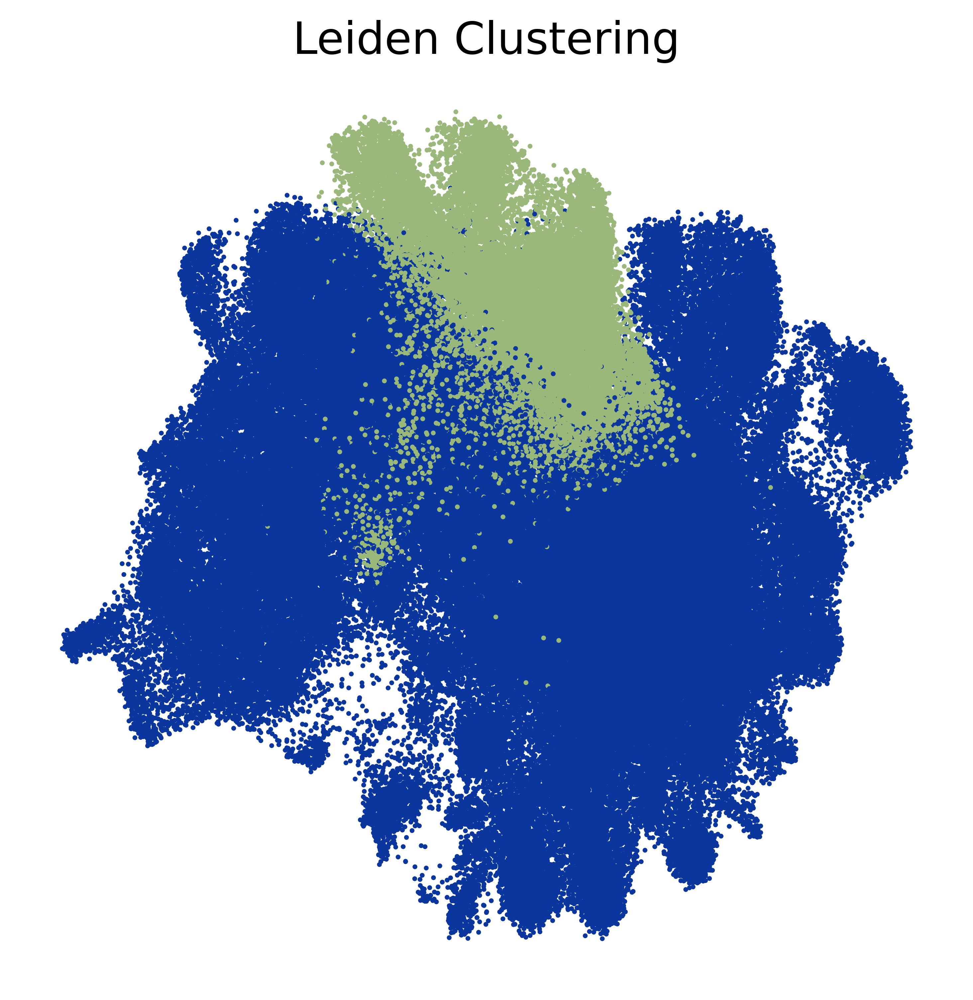

In [51]:
sc.set_figure_params(scanpy=True, fontsize=16,dpi=300,dpi_save=300,figsize=(6,6))
sc.pl.umap(combined_data_macro_norm_u_plot, color=["leiden_macro_scarches"],size=12,
          title = ["Leiden Clustering"],frameon=False, legend_fontsize=14,palette=colordict, legend_loc=False,
           save="_healthy_macro_leiden.png"
          )

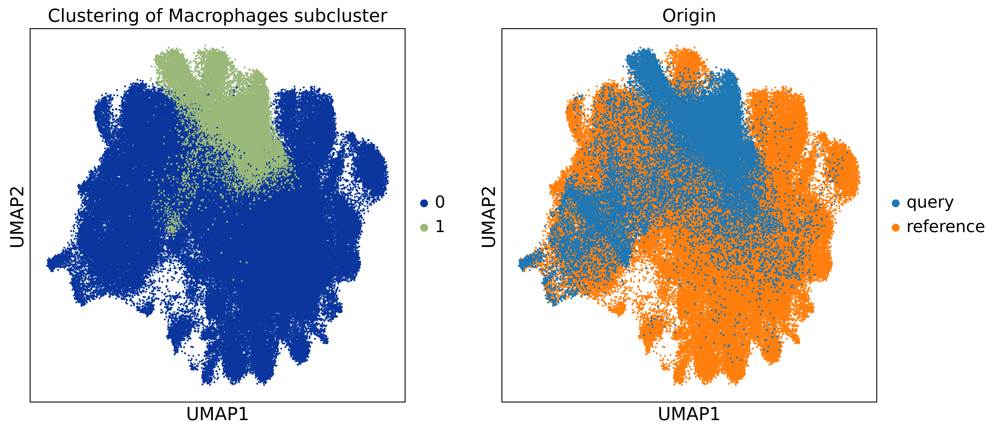

In [55]:
sc.pl.umap(combined_data_macro_norm_u_plot, color=["leiden_macro_scarches", "origin"],size=12, vmax=0.99,
          title = ["Clustering of Macrophages subcluster", "Origin"],  palette=colordict
          #,save = "figure_clustering_nk_subcluster_mki67.pdf"
          )

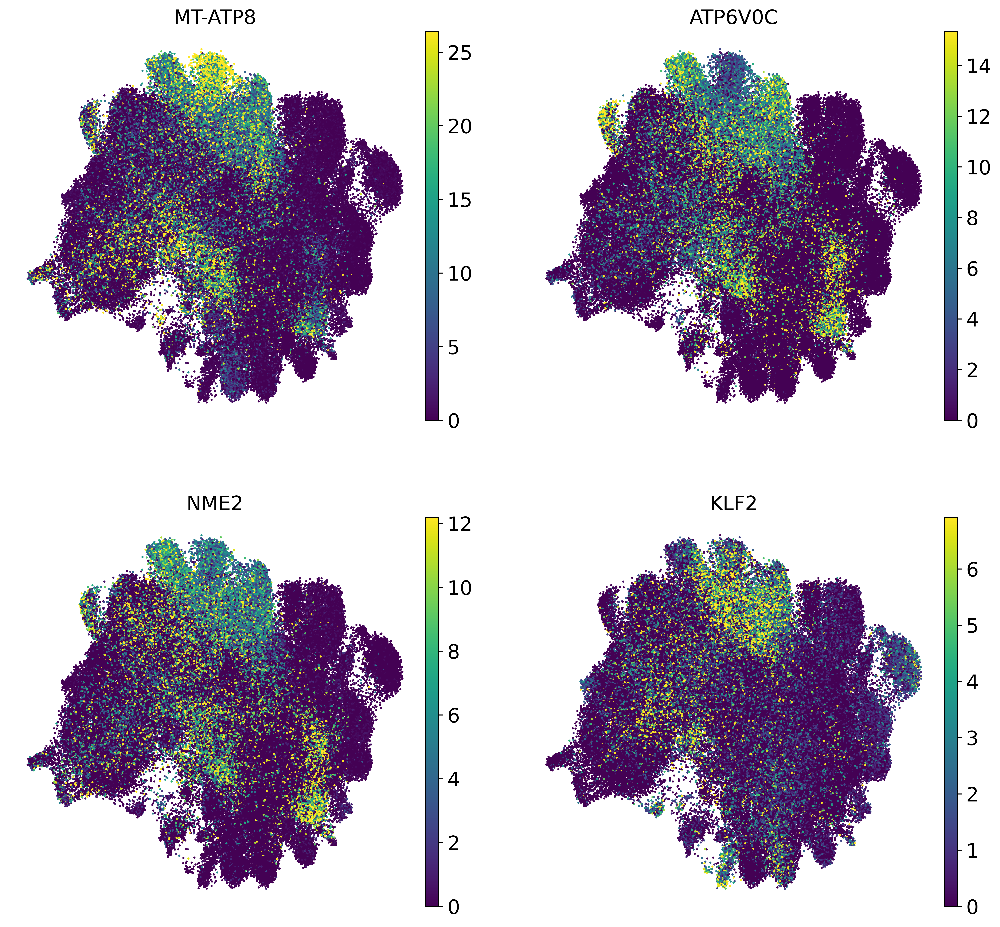

In [67]:
sc.pl.umap(combined_data_macro_norm_u_plot, color=["MT-ATP8","ATP6V0C","NME2","KLF2"],size=12, vmax="p95", sort_order=False, frameon=False,ncols=2,
           palette=colordict
          ,save = "_healthy_macro_top_de_genes_query_cluster.png"
          )

## Gene Set Enrichment Analysis (GSEA)

In [30]:
background_genes = combined_data_macro_norm_u.var["gene_symbols-0"].astype(str).tolist()

### 1. GSEA Macrophages

In [31]:
genes_up = table_de[table_de.group=="1"].names.tolist()
genes_down = table_de[table_de.group=="0"].names.tolist()

In [32]:
genes_up_no_code = [x for x in genes_up if x.startswith("ENSG")]
genes_up_code = [x for x in genes_up if x not in genes_up_no_code]
genes_down_no_code = [x for x in genes_down if x.startswith("ENSG")]
genes_down_code = [x for x in genes_down if x not in genes_down_no_code]

In [33]:
gp = GProfiler(return_dataframe=True, user_agent="g:GOSt")
enrichment_up = gp.profile(
    query=genes_up_code,
    organism="hsapiens",
    ordered=True,
    sources=["GO:BP"],  # , "GO:CC", "REAC", "CORUM", "HPO"],
    user_threshold=0.05,
    all_results=True,
    significance_threshold_method="fdr",
    background=background_genes,
    domain_scope='custom_annotated',
    no_evidences=False,
)
enrichment_down = gp.profile(
    query=genes_down_code,
    organism="hsapiens",
    ordered=True,
    sources=["GO:BP"],  # , "GO:CC", "REAC", "CORUM", "HPO"],
    user_threshold=0.05,
    all_results=True,
    significance_threshold_method="fdr",
    background=background_genes,
    domain_scope='custom_annotated',
    no_evidences=False,
)

In [ ]:
enr_up = gprofiler_custom_LISA.gprofiler_enrich(
    genes_up_code,
    n_modules_to_plot=20,
    ordered=True,
    sources=["GO:BP"],  # , "REAC", "CORUM", "HPO"],
    title="Healthy Macrophages: 20 most sign. UP-regulated modules",
)

Number of significant terms: 902. We will only plot 20.


In [ ]:
enr_down = gprofiler_custom_LISA.gprofiler_enrich(
    genes_down_code,
    n_modules_to_plot=20,
    ordered=True,
    sources=["GO:BP"],
    title="Healthy Macrophages: 20 most sign. DOWN-regulated modules",
)

In [ ]:
fz = 16
with plt.rc_context(
    {
        "figure.figsize": (5, 5),
        "xtick.labelsize": fz,
        "ytick.labelsize": fz,
        "legend.title_fontsize": "xx-large",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "xtick.bottom": True,
        "ytick.left": True,
    }
):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.barh(
        y=enr_up.name[:10],
        width=-np.log10(enr_up.p_value[:10][::-1]),
        height=0.4,
        color="g",
    )
    plt.xlabel("-log10(p-value)", fontsize=fz)
    plt.ylabel("GO term", fontsize=fz)
    plt.title(f"Healthy Macrophages: upregulated gene ontology terms", fontsize=fz)
    plt.xlim((0, 15))
    plt.grid(None)
    plt.savefig("healthy_macro_up_terms.png")

In [ ]:
fz = 16
with plt.rc_context(
    {
        "figure.figsize": (5, 5),
        "xtick.labelsize": fz,
        "ytick.labelsize": fz,
        "legend.title_fontsize": "xx-large",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "xtick.bottom": True,
        "ytick.left": True,
    }
):
    y = enr_down.name[:10].copy()
    # shorten label:
    for row, val in enumerate(enr_down.name[:10]):
        if (
            val
            == "antigen processing and presentation of exogenous peptide antigen via MHC class I, TAP-dependent"
        ):
            y[
                row
            ] = "antigen processing and presentation of exogenous\npeptide antigen via MHC class I, TAP-dependent"
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.barh(
        y=y,
        width=-np.log10(enr_down.p_value[:10]),
        height=0.4,
        color="firebrick",
    )
    plt.xlabel("-log10(p-value)", fontsize=fz)
    plt.ylabel("GO term", fontsize=fz)
    plt.title(f"Healthy Macrophages: downregulated gene ontology terms", fontsize=fz)
    plt.xlim((0, 15))
    plt.grid(None)
    plt.savefig("healthy_macro_down_terms.png")

In [11]:
sc.logging.print_versions()


The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.8
scanpy      1.8.2
sinfo       0.3.4
-----
PIL                                         8.4.0
aa8f2297d25b4dc6fd3d98411eb3ba53823c4f42    NA
absl                                        NA
adjustText                                  NA
anyio                                       NA
asciitree                                   NA
astunparse                                  1.6.3
attr                                        21.2.0
babel                                       2.9.1
backcall     